# Task 1 
## Implementing MC with brownian motion for BHE in high dimensions


The backward heat equation in arbitrary dimensional space with terminal condition $g(x)$ reads
\begin{equation}
    \partial_t u + \frac{1}{2} \Delta u = 0, u(T, x) = g(x) = |x|^2
\end{equation}
and has the analytical solution
\begin{equation}
    u(t, x) = |x|^2 + d(T-t)
\end{equation}
where $d$ denotes dimension and $T$ is the maturity time

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Analytical solution

In [2]:
def heexact(t, x, T):
    x = np.atleast_1d(x)
    d = x.shape[-1]
    return np.sum(x**2, axis=-1) + d*(T-t)

The equation can be written as an SDE and $X_s$ can be written as a stochastic process
\begin{equation}
    dX_s = dW_s
\end{equation}
the lack of drift term is a consequence of the PDE as $\mu = 0$ and $\sigma = 1$, the general formulation $dX_s = \mu(X_s, s)dt + \sigma(X_s, s)dW_t$

Thus, the the PDE can be approximated by

\begin{equation}
    u(t,x) = \mathbb{E}[g(X_t) | X_t = x] = \mathbb{E}[g(x + W_{T-t})]
\end{equation}
This comes from the integration of the previous equation. Now, $W_{T-t} \sim N(0, T-t)$

The solution can then be attained with MC:
\begin{equation}
    \mathbb{E}[g(x + W_{T-t})] \approx \frac{1}{N}\sum_{i = 1}^N g(x + W^{(i)}_{T-t})
\end{equation}
Where $W^{(i)}_{T-t} = \sqrt{T-t}Z^{(i)}$ and $Z^{(i)} \sim N(0, 1)$ i.i.d.

Here $X_T$ can be directly derived, but the equation can also be solved with Euler Marauyama $W = \sqrt{\Delta t}Z$

In [3]:
def W(dt, N, d):
    return np.sqrt(dt)*np.random.randn(N, d)

def g(x):
    return np.sum(x**2, axis= -1)

def g2(x):
    return 0.3*np.exp(-(x-0.5)**2 / 0.2)

In [4]:
def bhe_MC(x, t, T, M, N, psi):
    x = np.atleast_1d(x)
    d = len(x)
    dt = (T-t) / M
    X = np.tile(x, (N, 1))
    for _ in range(M):
        X = X + W(dt, N, d)
    vals = psi(X)
    return vals.mean(), vals.std() / np.sqrt(N)  

The results can be tested and visualized (in 1 and 2 d)

In [5]:
def plot1d(x, M, N, sol, exact):
    plt.plot(x, exact, label = "Exact solution")
    plt.plot(x, sol, label = 'MC solution')
    plt.title("Exact and simulated solutions to the 1D BHE")
    plt.legend()
    plt.show()
    

In [6]:
def plot2d(sol, x1, x2, sim: bool, ax, vmin=None, vmax=None):
    lab = "MC simulated solution" if sim else "Exact solution"
    sns.heatmap(sol, cmap='coolwarm', vmin=vmin, vmax=vmax, ax=ax,
                xticklabels=np.round(x1, 2), yticklabels=np.round(x2, 2),
                cbar_kws={"label": "$u(0, x)$"})
    ax.invert_yaxis()
    ax.set_xticks(ax.get_xticks()[::5]); ax.set_yticks(ax.get_yticks()[::5])
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(lab)


In [7]:
def plot_dim(t, T, M, N, psi, dims):
    res = np.zeros(dims)
    exacts = np.zeros(dims)
    x = np.array([])
    for d in range(dims):
        x = np.append(x, 1.0)
        res[d] = bhe_MC(x, t, T, M, N, psi)[0]
        exacts[d] = heexact(t, x, T)

    plt.plot(range(1,dims + 1), res, label = "Simulated solutions")
    plt.plot(range(1, dims + 1), exacts, label = "Exact solutions")
    plt.title("Solution at $x_i = 1$ for all $x$ at $t = 0$")
    plt.show()

First, the 1D case with only one value of $x$

In [8]:
M = 1
N = 100
x = np.array([1.0, 1.0, 1.0])
t = 0.0
T = 1.0
sol = bhe_MC(x, t, T, M, N, psi = g)
exact = heexact(t, x, T)
print(f"Simulated Solution: {sol[0]}")
print(f"Exact Solution {exact}")


Simulated Solution: 6.439999608002291
Exact Solution 6.0


Test with another $g(x) = e^{(x-0.5)^2/2}$

In [9]:
sol = bhe_MC(x, t, T, M, N, psi = g2)
print(f"Simulated Solution: {sol[0]}")

Simulated Solution: 0.08196719411668378


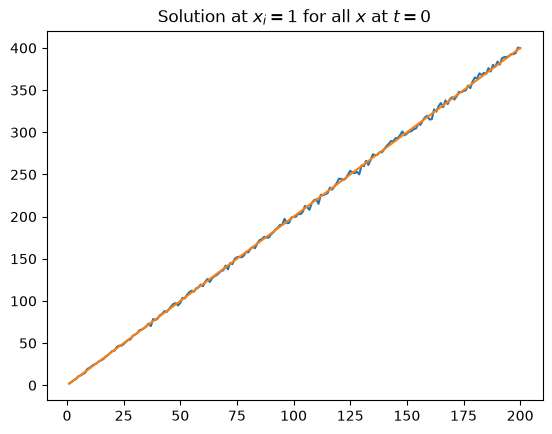

In [10]:
plot_dim(t, T, M, N, g, dims = 200)

Now simulate a whole path for $x \in [x_{min}, x_{max}]$ in 1D

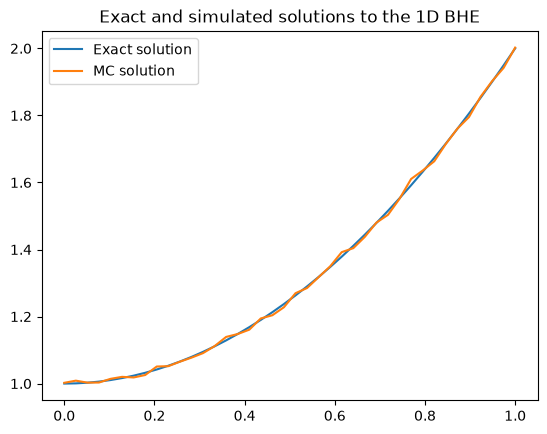

In [11]:
M = 1
N = 100000
x_min = 0.0
x_max = 1.0
x_space = np.linspace(x_min, x_max, 40)

sol_path = np.zeros_like(x_space)
exact_path = np.array([heexact(t, x, T) for x in x_space])

for i, x in enumerate(x_space):
    sol_path[i] = bhe_MC(x, t, T, M, N, psi=g)[0]

plot1d(x_space, M, N, sol=sol_path, exact = exact_path)

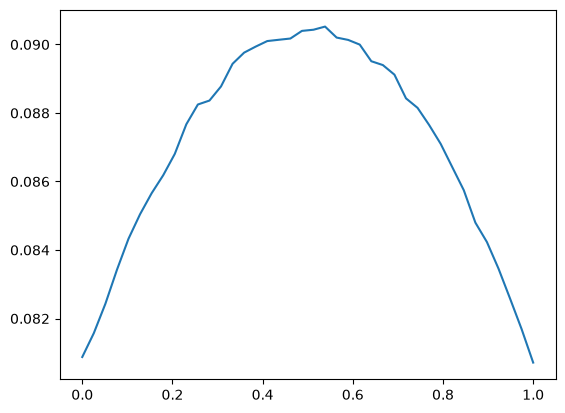

In [12]:
M = 1
N = 1000000
x_min = 0.0
x_max = 1.0
x_space = np.linspace(x_min, x_max, 40)

sol_path = np.zeros_like(x_space)
exact_path = np.array([heexact(t, x, T) for x in x_space])

for i, x in enumerate(x_space):
    sol_path[i] = bhe_MC(x, t, T, M, N, psi=g2)[0]

plt.plot(x_space, sol_path)
plt.show()

Evaluate the function on a 2D grid also

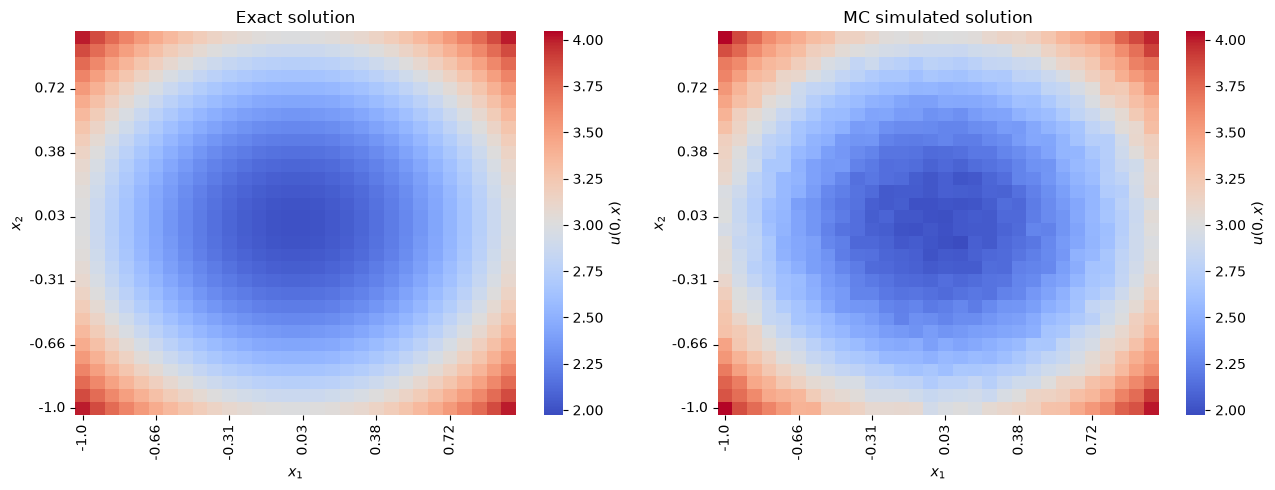

In [13]:
M = 1
N = 10000
x_min = -1.0
x_max = 1.0

x1 = np.linspace(x_min, x_max, 30) 
x2 = np.linspace(x_min, x_max, 30) 

X1, X2 = np.meshgrid(x1, x2)
points = np.stack([X1.ravel(), X2.ravel()], axis=-1)

sol_grid = np.array([bhe_MC(p, t, T, M, N, psi=g)[0] for p in points]).reshape(X1.shape)
exact_grid = heexact(t, points, T).reshape(X1.shape)

vmin = min(sol_grid.min(), exact_grid.min())
vmax = max(sol_grid.max(), exact_grid.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))   # 1 row, 2 columns
plot2d(exact_grid, x1, x2, sim=False, ax=axes[0], vmin=vmin, vmax=vmax)
plot2d(sol_grid,  x1, x2, sim=True,  ax=axes[1], vmin=vmin, vmax=vmax)
plt.tight_layout()
plt.show()


## Error Analysis

This part produces a graph over the error as a function of M for a number of different dimensions, for a point $\mathbf{x} = [x_1, \dots, x_d] = [1, \dots , 1]$

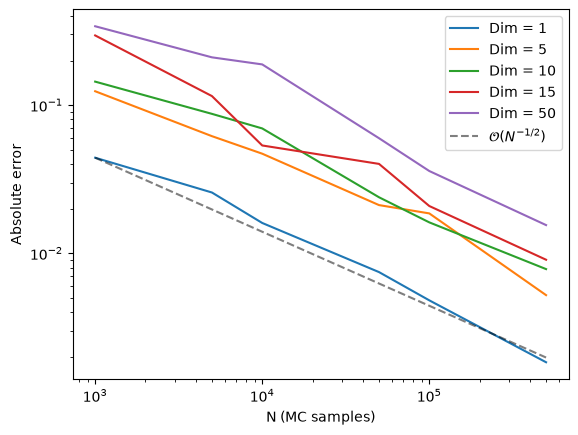

In [29]:
N_list = np.array([1_000, 5_000, 10_000, 50_000, 100_000, 500_000])
d_list = [1, 5, 10, 15, 50]
M = 1          # one step is exact for driftless Brownian motion
t, T = 0.0, 1.0
n_rep = 10     # repeats to smooth out noise

res = []
for d in d_list:
    x = np.ones(d)
    exact = heexact(t, x, T)
    res.append([np.mean([np.abs(exact - bhe_MC(x, t, T, M, N, psi=g)[0])
                         for _ in range(n_rep)]) for N in N_list])

for i, d in enumerate(d_list):
    plt.loglog(N_list, res[i], label=f'Dim = {d}')

plt.loglog(N_list, res[0][0] * (N_list / N_list[0])**-0.5, 'k--', label=r'$\mathcal{O}(N^{-1/2})$', alpha = 0.5)
plt.xlabel('N (MC samples)'); plt.ylabel('Absolute error')
plt.legend()
plt.show()


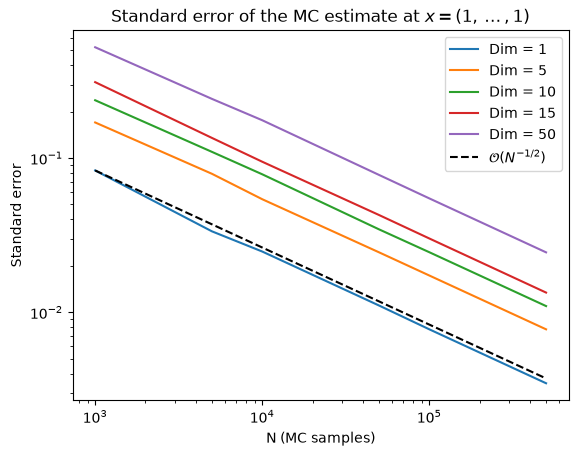

In [30]:
N_list = np.array([1_000, 5_000, 10_000, 50_000, 100_000, 500_000])
d_list = [1, 5, 10, 15, 50]
M = 1
t, T = 0.0, 1.0

se = []
for d in d_list:
    x = np.ones(d)
    se.append([bhe_MC(x, t, T, M, N, psi=g)[1] for N in N_list])

for i, d in enumerate(d_list):
    plt.loglog(N_list, se[i], label=f'Dim = {d}')

plt.loglog(N_list, se[0][0] * (N_list / N_list[0])**-0.5, 'k--', label=r'$\mathcal{O}(N^{-1/2})$')
plt.xlabel('N (MC samples)'); plt.ylabel('Standard error')
plt.title('Standard error of the MC estimate at $x = (1, \\dots, 1)$')
plt.legend()
plt.show()
